<a href="https://colab.research.google.com/github/athfizh/PCVK26_05_Hafizh/blob/main/Modul%209/P9_TugasPraktikum_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama  : Athaulla Hafizh

Absen : 05

Kelas : TI-3F

NIM   : 244107020030

**Modul 9 - Morfologi**

---

In [1]:
# Sel Identitas
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Athaulla Hafizh'
NIM  = '244107020030'
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA   :', NAMA)
print('NIM    :', NIM)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Athaulla Hafizh
NIM    : 244107020030
WAKTU  : 2026-10-27 08:50:22 WIB
SISTEM : 3.13.16 Linux-6.6.159+-x86_64-with-glibc2.39
TOKEN  : 201782df4ae9dfed


**Langkah Persiapan: Drive, Library, dan Folder Kerja**

Drive di-mount lalu library diimport sesuai modul (OpenCV, NumPy, Matplotlib). Tiga citra dipakai:

- `Plat Nomor.png` untuk Langkah 3 sampai 12, dan sebagai pembanding di Langkah 13 sampai 17.
- `kitten01.jpg` untuk Top-Hat dan Black-Hat, sama seperti modul.
- `lily.jpg` untuk Skeleton dan Thinning, sama seperti modul.

Fungsi `cari_citra` mengecek beberapa kemungkinan folder, jadi kalau lokasi file berbeda cukup ubah `BASE`. Kalau file tetap tidak ketemu, notebook berhenti dengan pesan jelas, bukan memproses citra kosong.

In [2]:
%matplotlib inline

# Mount Google Drive (hanya bisa di Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Bukan Colab: Drive tidak di-mount, file dibaca dari folder lokal.')

# Import library sesuai modul
import cv2
import numpy as np
from matplotlib import pyplot as plt
import os, glob

BASE = '/content/drive/MyDrive/COLLEGE/SEM 5/PCVK/MODUL/Pertemuan 9'


def cari_citra(pola):
    """Cari file citra di beberapa kemungkinan folder."""
    folder = [BASE,
              '/content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/MODUL 9',
              '/content/drive/MyDrive/COLLEGE/SEM 5/PCVK/Modul9',
              '/content',
              '.']
    for f in folder:
        hasil = sorted(glob.glob(os.path.join(f, pola)))
        if hasil:
            return hasil[0]
    hasil = glob.glob('/content/drive/MyDrive/COLLEGE/SEM 5/PCVK/**/' + pola, recursive=True)
    if hasil:
        return sorted(hasil)[0]
    raise FileNotFoundError(
        f'{pola} tidak ditemukan. Taruh file di {BASE}/ atau di folder notebook ini.'
    )


def baca_citra(path, kode=cv2.IMREAD_COLOR):
    """Baca citra dan pastikan tidak kosong."""
    img = cv2.imread(path, kode)
    if img is None:
        raise FileNotFoundError('Gagal membaca file: ' + path)
    return img


path_plat = cari_citra('Plat Nomor.png')
path_kit  = cari_citra('kitten01*')
path_lily = cari_citra('lily.jpg')

print('Plat Nomor :', os.path.basename(path_plat))
print('Kitten     :', os.path.basename(path_kit))
print('Lily       :', os.path.basename(path_lily))


def tampilkan(judul, baris, figsize=None):
    """Tampilkan citra dalam grid. Tiap item: (gambar, judul) atau (gambar, judul, vmax)."""
    nrow = len(baris)
    ncol = max(len(b) for b in baris)
    fig, axes = plt.subplots(nrow, ncol,
                             figsize=figsize or (4.2 * ncol, 3.6 * nrow),
                             squeeze=False)
    for r, isi in enumerate(baris):
        for c in range(ncol):
            ax = axes[r][c]
            ax.set_axis_off()
            if c < len(isi):
                gambar, teks = isi[c][0], isi[c][1]
                vmax = isi[c][2] if len(isi[c]) > 2 else None
                ax.imshow(gambar, cmap='gray', vmin=0, vmax=vmax)
                ax.set_title(teks, fontsize=10)
    fig.suptitle(NIM + ' - ' + judul, fontsize=11)
    plt.tight_layout()
    plt.show()

Mounted at /content/drive
Plat Nomor : Plat Nomor.png
Kitten     : kitten01 (1).jpg
Lily       : lily.jpg


---
# **D. Praktikum Morfologi**

**Awalan: Plat Nomor.png Menjadi Citra Biner**

Operasi di Langkah 3 sampai 12 butuh citra biner, jadi plat nomor disiapkan dulu:

1. Dibaca sebagai grayscale.
2. Pinggiran dipotong sedikit supaya bingkai hitam tidak ikut dihitung sebagai objek.
3. Threshold Otsu lalu diinversi (`THRESH_BINARY_INV`), jadi huruf bernilai 255 (objek) dan latar 0.

Nilai ambang Otsu   : 137.0
Ukuran citra biner  : (159, 411)
Piksel putih (objek): 9322


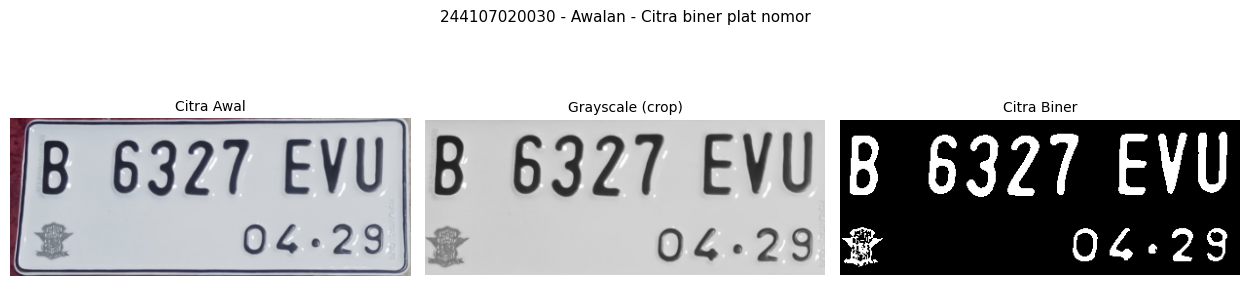

In [3]:
# Baca plat nomor lalu ubah ke grayscale
img_bgr  = baca_citra(path_plat)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Potong pinggiran plat (6% kiri/kanan, 6% atas/bawah)
h, w = img_gray.shape
crop = img_gray[int(0.06 * h):int(0.94 * h), int(0.06 * w):int(0.96 * w)]

# Binerisasi Otsu + invers: huruf gelap jadi putih (objek)
nilai, biner = cv2.threshold(crop, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print('Nilai ambang Otsu   :', nilai)
print('Ukuran citra biner  :', biner.shape)
print('Piksel putih (objek):', np.count_nonzero(biner))

tampilkan('Awalan - Citra biner plat nomor',
          [[(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), 'Citra Awal'),
            (crop, 'Grayscale (crop)'),
            (biner, 'Citra Biner')]])

---
## **Langkah 3 - Dilasi Tanpa Library (SED Square 5x5)**

Piksel putih sebelum dilasi : 9322
Piksel putih sesudah dilasi : 16130


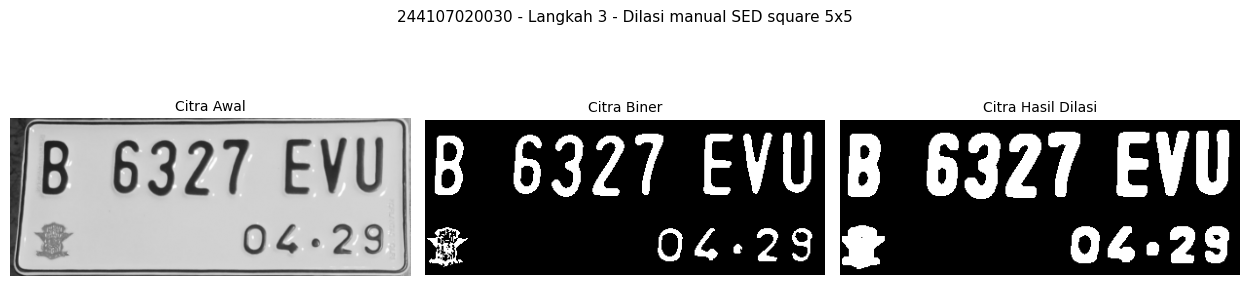

In [4]:
# Dilasi tanpa library
def dilasi_citra(F, SED):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    # titik pusat SED
    r, c = SED.shape[0] // 2, SED.shape[1] // 2
    # proses dilasi
    for i in range(r, p - r):
        for j in range(c, q - c):
            temp    = F[i - r:i + r + 1, j - c:j + c + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD


# Generate structure element dilasi (SED) square 5x5
SED_square5 = np.ones((5, 5), dtype=np.uint8)
imgD_manual = dilasi_citra(biner, SED_square5)

print('Piksel putih sebelum dilasi :', np.count_nonzero(biner))
print('Piksel putih sesudah dilasi :', np.count_nonzero(imgD_manual))

tampilkan('Langkah 3 - Dilasi manual SED square 5x5',
          [[(img_gray, 'Citra Awal'),
            (biner, 'Citra Biner'),
            (imgD_manual, 'Citra Hasil Dilasi')]])

## **Langkah 4 - Dilasi dengan Library OpenCV (Square 3x3)**

`cv2.dilate` dengan kernel 3x3. Fungsi manual dijalankan dengan SED 3x3 yang sama sebagai pembanding. Pinggir tidak dibandingkan karena loop manual melewati pinggir, sedangkan OpenCV tetap menghitungnya.

[[1 1 1]
 [1 1 1]
 [1 1 1]]
Selisih manual 3x3 vs cv2.dilate (bagian dalam): 0


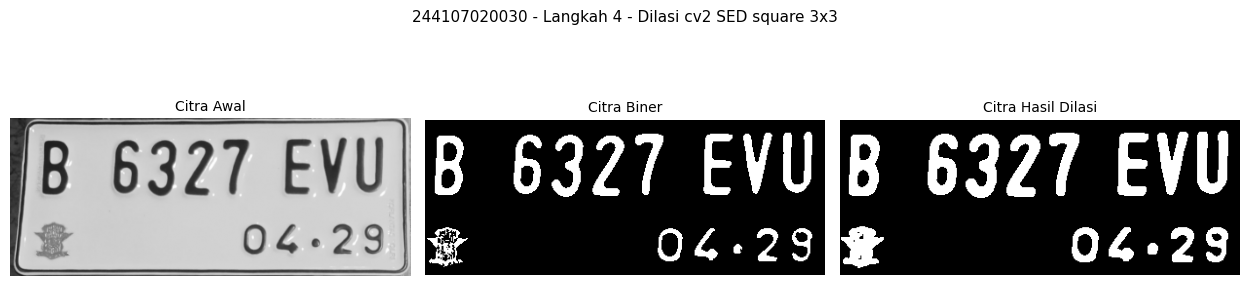

In [5]:
# Dilasi dengan library morphology OpenCV
kernel = np.ones((3, 3), np.uint16)
dilasi_lib = cv2.dilate(biner, kernel, iterations=1)
print(kernel)

# Pembanding: fungsi manual dengan SED 3x3
imgD_manual3 = dilasi_citra(biner, np.ones((3, 3), dtype=np.uint8))
selisih = np.max(np.abs(imgD_manual3[1:-1, 1:-1].astype(int) - dilasi_lib[1:-1, 1:-1].astype(int)))
print('Selisih manual 3x3 vs cv2.dilate (bagian dalam):', selisih)

tampilkan('Langkah 4 - Dilasi cv2 SED square 3x3',
          [[(img_gray, 'Citra Awal'),
            (biner, 'Citra Biner'),
            (dilasi_lib, 'Citra Hasil Dilasi')]])

**Pembahasan Singkat**

Dilasi menebalkan huruf karena area putih melebar. Hasil manual sama dengan `cv2.dilate` di bagian dalam citra (selisih 0), jadi implementasinya sudah benar. Bedanya hanya di pinggir karena loop manual melewati baris/kolom terluar.

## **Langkah 5 - Erosi Tanpa Library (SE Square 5x5)**

Erosi kebalikan dilasi: piksel diambil dari nilai minimum jendela, jadi area putih menyusut.

Piksel putih sebelum erosi : 9322
Piksel putih sesudah erosi : 3086


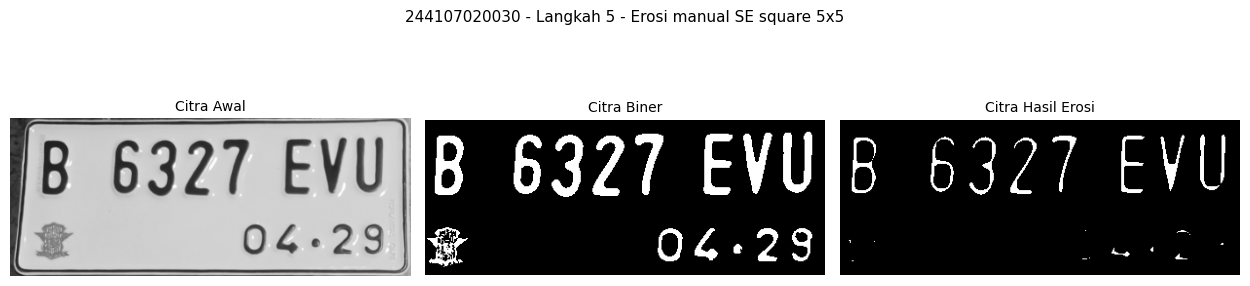

In [6]:
# Erosi tanpa library
def erosi_citra(F, SE):
    # size image
    m, n = F.shape
    imgE = np.zeros((m, n), dtype=np.uint8)
    # titik pusat SE
    r, c = SE.shape[0] // 2, SE.shape[1] // 2
    # proses erosi
    for i in range(r, m - r):
        for j in range(c, n - c):
            temp    = F[i - r:i + r + 1, j - c:j + c + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE


# Generate structure element erosi (SE) square 5x5
SE_square5 = np.ones((5, 5), dtype=np.uint8)
imgE_manual = erosi_citra(biner, SE_square5)

print('Piksel putih sebelum erosi :', np.count_nonzero(biner))
print('Piksel putih sesudah erosi :', np.count_nonzero(imgE_manual))

tampilkan('Langkah 5 - Erosi manual SE square 5x5',
          [[(img_gray, 'Citra Awal'),
            (biner, 'Citra Biner'),
            (imgE_manual, 'Citra Hasil Erosi')]])

## **Langkah 6 - Erosi dengan Library OpenCV (Square 5x5)**

Sama seperti langkah sebelumnya, tapi memakai `cv2.erode`. Hasilnya dibandingkan dengan erosi manual di bagian dalam citra.

Selisih erosi manual vs cv2.erode (bagian dalam): 0


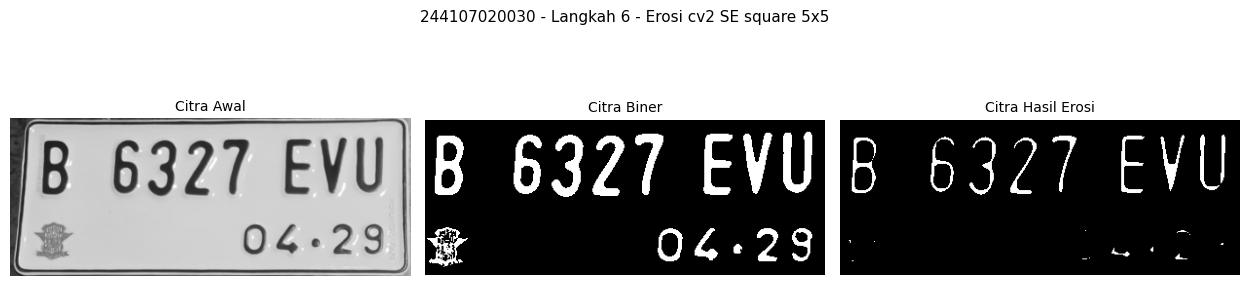

In [7]:
# Erosi dengan library morphology OpenCV
kernel = np.ones((5, 5), np.uint8)
erosi_lib = cv2.erode(biner, kernel, iterations=1)

selisih = np.max(np.abs(imgE_manual[2:-2, 2:-2].astype(int) - erosi_lib[2:-2, 2:-2].astype(int)))
print('Selisih erosi manual vs cv2.erode (bagian dalam):', selisih)

tampilkan('Langkah 6 - Erosi cv2 SE square 5x5',
          [[(img_gray, 'Citra Awal'),
            (biner, 'Citra Biner'),
            (erosi_lib, 'Citra Hasil Erosi')]])

## **Langkah 7 - Opening (Square 3x3)**

Opening = erosi lalu dilasi. Tujuannya menghilangkan objek kecil atau noise tanpa banyak mengubah objek besar.

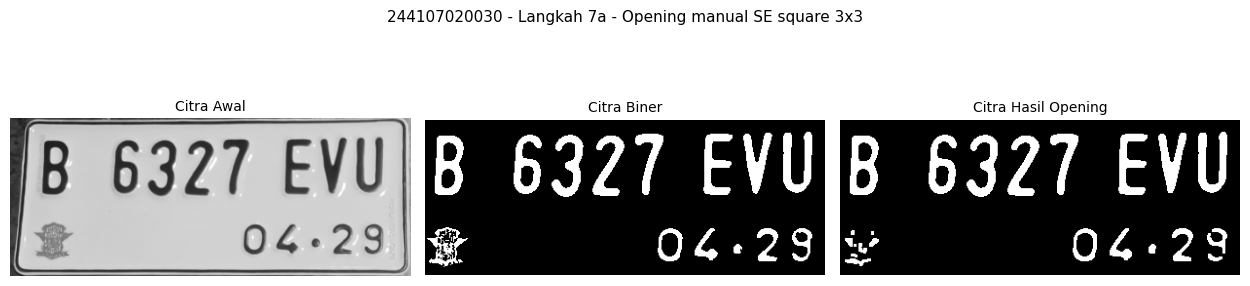

In [8]:
# Opening tanpa library: erosi dulu, lalu dilasi
SE3 = np.ones((3, 3), dtype=np.uint8)
imgO_manual = dilasi_citra(erosi_citra(biner, SE3), SE3)

tampilkan('Langkah 7a - Opening manual SE square 3x3',
          [[(img_gray, 'Citra Awal'),
            (biner, 'Citra Biner'),
            (imgO_manual, 'Citra Hasil Opening')]])

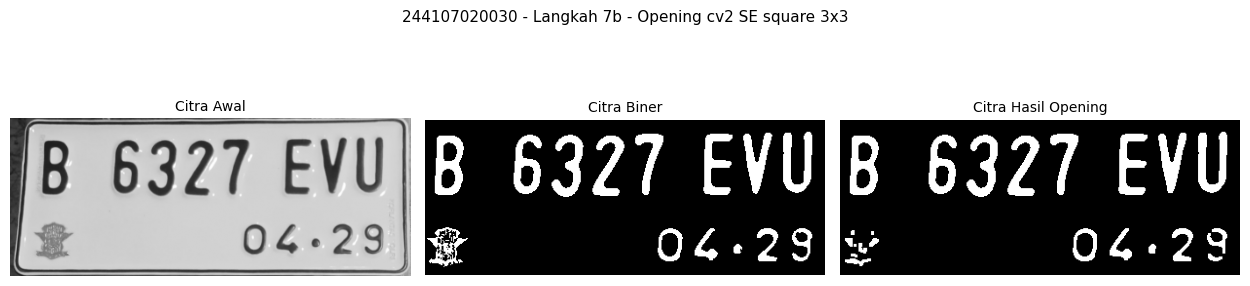

In [9]:
# Opening dengan library morphology
kernel = np.ones((3, 3), np.uint8)
opening_lib = cv2.morphologyEx(biner, cv2.MORPH_OPEN, kernel)

tampilkan('Langkah 7b - Opening cv2 SE square 3x3',
          [[(img_gray, 'Citra Awal'),
            (biner, 'Citra Biner'),
            (opening_lib, 'Citra Hasil Opening')]])

## **Langkah 8 - Closing (Square 3x3)**

Closing = dilasi lalu erosi, kebalikan opening. Operasi ini menutup lubang atau celah kecil di dalam objek.

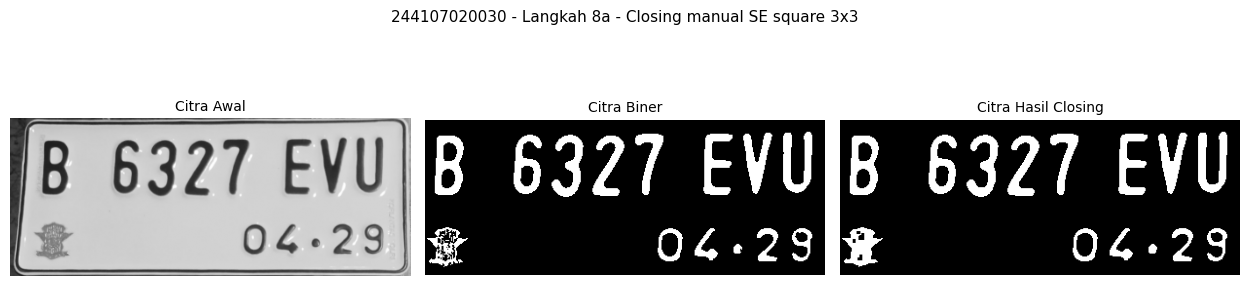

In [10]:
# Closing tanpa library: dilasi dulu, lalu erosi
imgC_manual = erosi_citra(dilasi_citra(biner, SE3), SE3)

tampilkan('Langkah 8a - Closing manual SE square 3x3',
          [[(img_gray, 'Citra Awal'),
            (biner, 'Citra Biner'),
            (imgC_manual, 'Citra Hasil Closing')]])

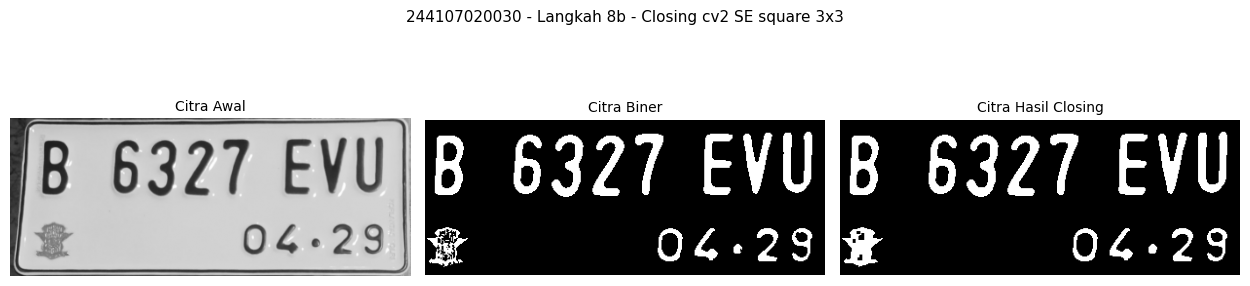

In [11]:
# Closing dengan library morphology
closing_lib = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))

tampilkan('Langkah 8b - Closing cv2 SE square 3x3',
          [[(img_gray, 'Citra Awal'),
            (biner, 'Citra Biner'),
            (closing_lib, 'Citra Hasil Closing')]])

**Pembahasan Singkat**

Opening menghapus bintik putih kecil dan bagian yang lebih tipis dari SE, sedangkan huruf tebal tetap utuh. Closing menutup celah hitam tipis di dalam huruf. Hasil manual dan library sama karena urutan operasinya memang sama.

## **Langkah 9 - Dilasi dengan SED Cross 3x3 dan 5x5**

SED cross dibuat lewat fungsi kecil supaya bentuk 3x3 dan 5x5 tidak perlu ditulis satu per satu.

SED = Cross 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]


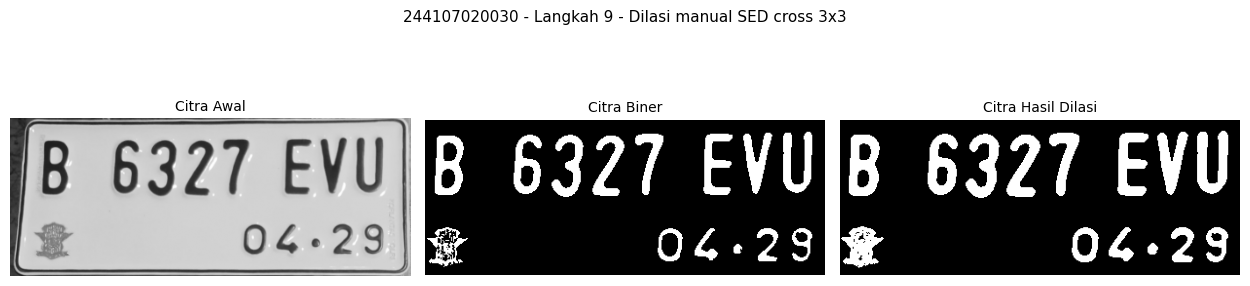

SED = Cross 5
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]


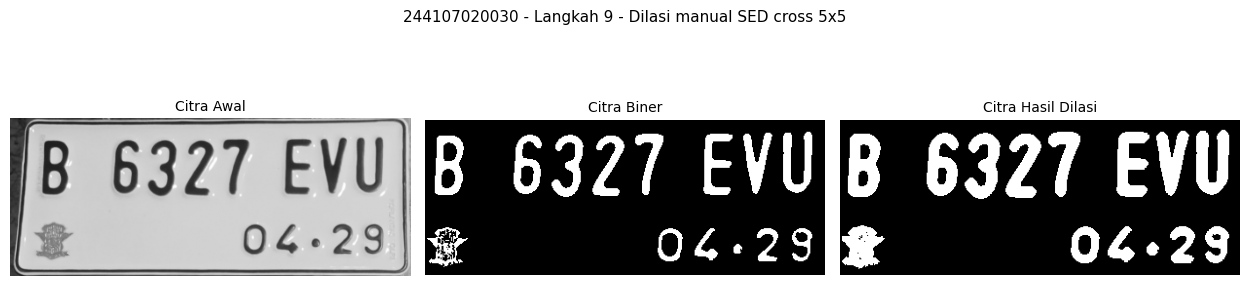

In [12]:
# SED cross: baris tengah dan kolom tengah bernilai 1
def sed_cross(n):
    se = np.zeros((n, n), dtype=np.uint8)
    tengah = n // 2
    se[tengah, :] = 1
    se[:, tengah] = 1
    return se


for ukuran in [3, 5]:
    SED = sed_cross(ukuran)
    hasil = dilasi_citra(biner, SED)
    print(f'SED = Cross {ukuran}')
    print(SED)
    tampilkan(f'Langkah 9 - Dilasi manual SED cross {ukuran}x{ukuran}',
              [[(img_gray, 'Citra Awal'),
                (biner, 'Citra Biner'),
                (hasil, 'Citra Hasil Dilasi')]])

## **Langkah 10 - Dilasi dengan SED Circular 3x3 dan 5x5**

SED lingkaran dibuat dengan `cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))`. Pembuatan kernel ini bukan operasi morfologi, jadi fungsi dilasi manual tetap dipakai.

SED = Circle 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]


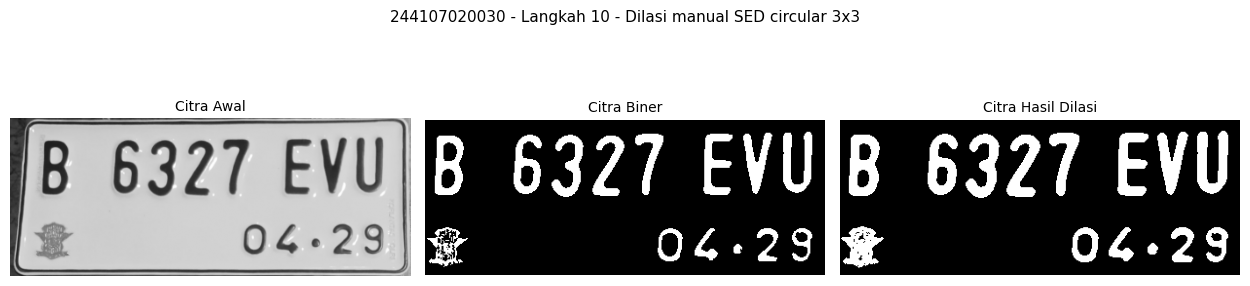

SED = Circle 5
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


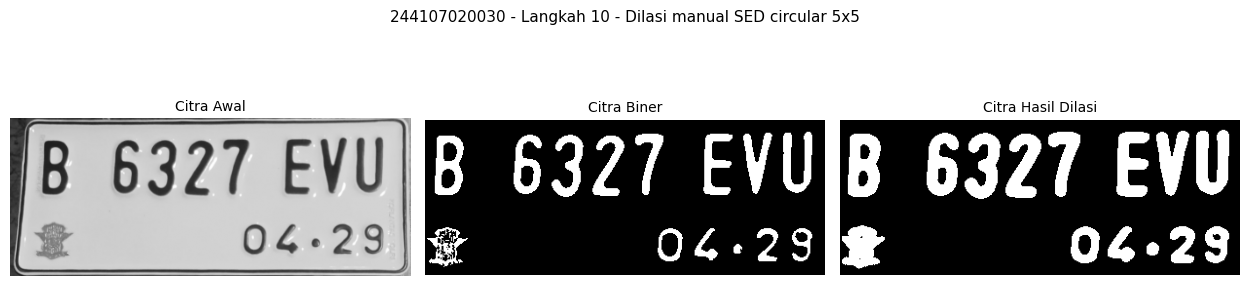

In [13]:
for ukuran in [3, 5]:
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ukuran, ukuran))
    hasil = dilasi_citra(biner, SED)
    print(f'SED = Circle {ukuran}')
    print(SED)
    tampilkan(f'Langkah 10 - Dilasi manual SED circular {ukuran}x{ukuran}',
              [[(img_gray, 'Citra Awal'),
                (biner, 'Citra Biner'),
                (hasil, 'Citra Hasil Dilasi')]])

## **Langkah 11 - Erosi dengan SE Rectangle 3x5 dan 5x7**

SE persegi panjang dibuat dengan `cv2.MORPH_RECT`. Ukuran ditulis (lebar, tinggi), jadi 3x5 berarti tinggi 3 dan lebar 5.

SE = Rectangle 3x5
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


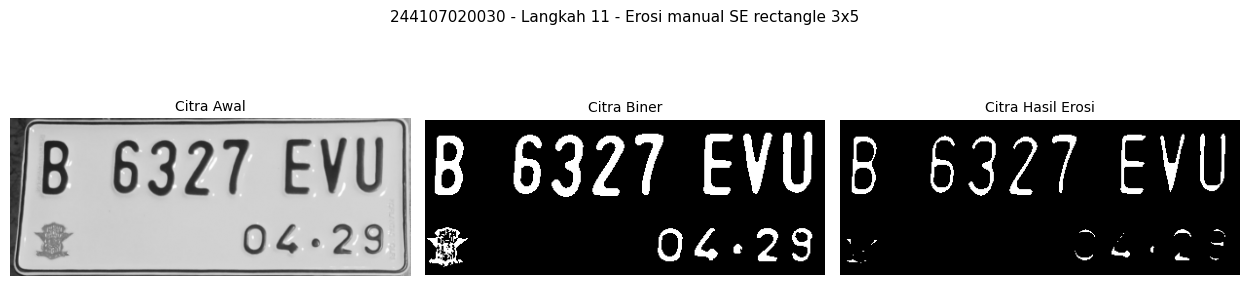

SE = Rectangle 5x7
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]


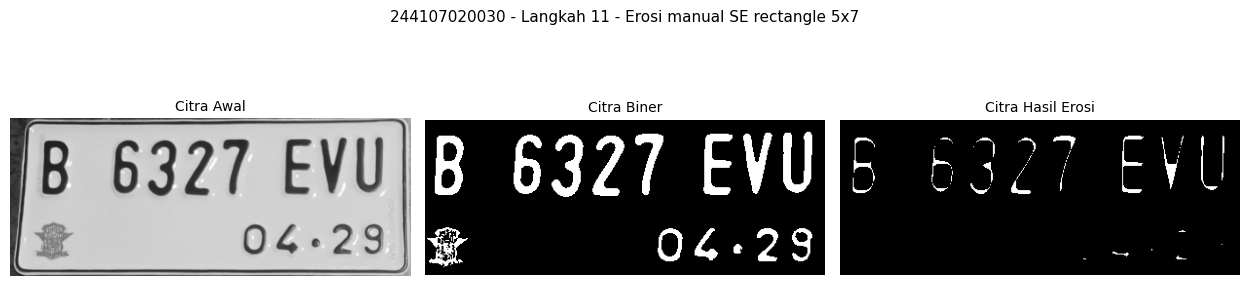

In [14]:
for tinggi, lebar in [(3, 5), (5, 7)]:
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (lebar, tinggi))
    hasil = erosi_citra(biner, SE)
    print(f'SE = Rectangle {tinggi}x{lebar}')
    print(SE)
    tampilkan(f'Langkah 11 - Erosi manual SE rectangle {tinggi}x{lebar}',
              [[(img_gray, 'Citra Awal'),
                (biner, 'Citra Biner'),
                (hasil, 'Citra Hasil Erosi')]])

## **Langkah 12 - Erosi dengan SE Line Vertikal 3 dan 5**

SE garis vertikal dibuat dengan `cv2.MORPH_ELLIPSE` berukuran (1, k), jadi hanya satu kolom yang aktif. Erosi dengan SE ini menyisakan goresan vertikal setinggi SE.

SE = Line Vertikal 3
[[1]
 [1]
 [1]]


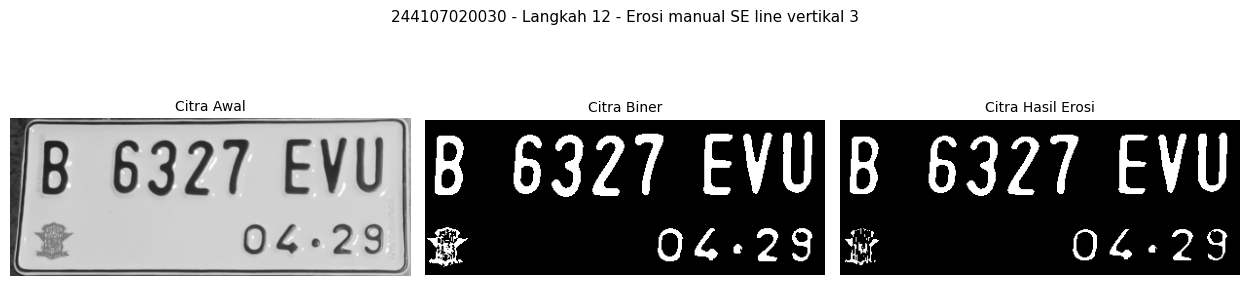

SE = Line Vertikal 5
[[1]
 [1]
 [1]
 [1]
 [1]]


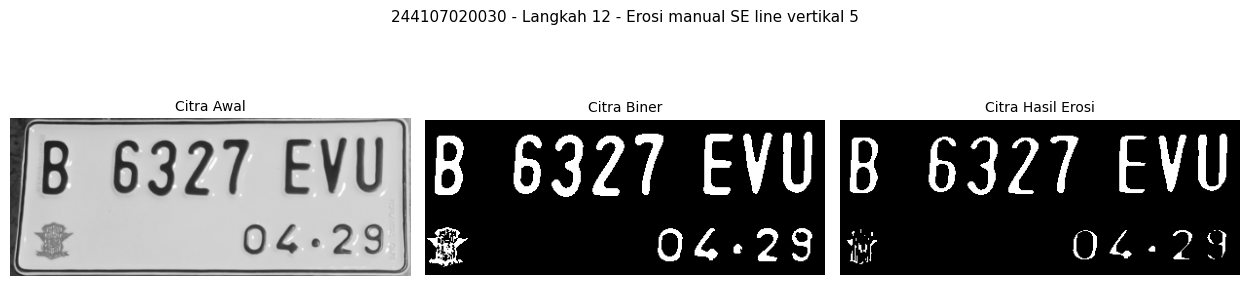

In [15]:
for k in [3, 5]:
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))
    hasil = erosi_citra(biner, SE)
    print(f'SE = Line Vertikal {k}')
    print(SE)
    tampilkan(f'Langkah 12 - Erosi manual SE line vertikal {k}',
              [[(img_gray, 'Citra Awal'),
                (biner, 'Citra Biner'),
                (hasil, 'Citra Hasil Erosi')]])

**Pembahasan Singkat**

Bentuk SED menentukan arah perubahan. Cross melebar ke vertikal dan horizontal, circular lebih halus ke segala arah, rectangle menyisakan bagian yang sesuai ukurannya, dan line vertikal hanya mempertahankan goresan tegak. Semakin besar ukuran SE, semakin banyak bagian objek yang hilang atau bertambah.

---
## **Langkah 13 - Transformasi Top-Hat (SE 3x3)**

Top-hat = citra asal dikurangi hasil opening, jadi yang muncul adalah objek putih kecil atau tipis yang hilang saat opening.
Panel hasil memakai `vmax` sesuai nilai maksimumnya, karena nilai top-hat tidak sampai 255.

Kitten     -> nilai maksimum Top-Hat: 147
Plat Nomor -> nilai maksimum Top-Hat: 110


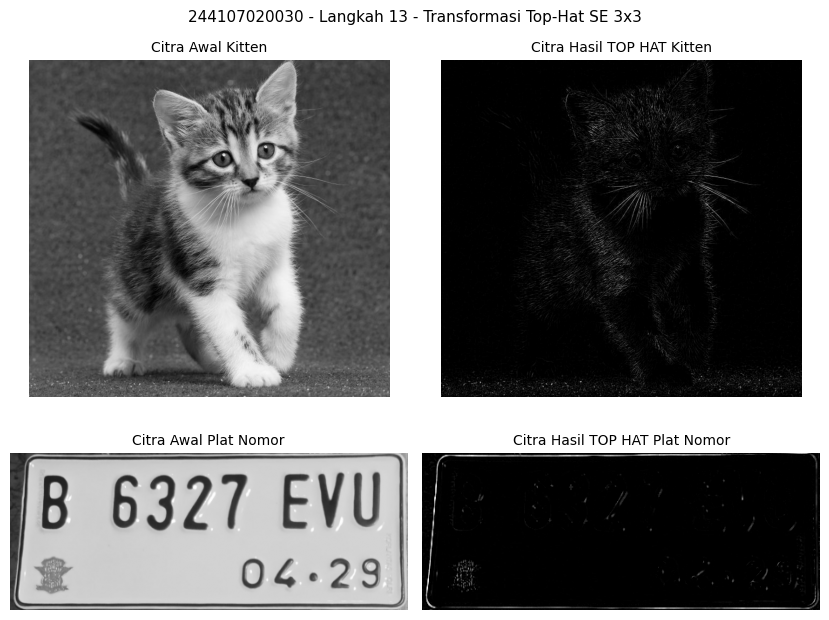

In [16]:
# Kernel untuk Top-Hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img_kit = baca_citra(path_kit, cv2.IMREAD_GRAYSCALE)

tophat_kit  = cv2.morphologyEx(img_kit,  cv2.MORPH_TOPHAT, kernel)
tophat_plat = cv2.morphologyEx(img_gray, cv2.MORPH_TOPHAT, kernel)

print('Kitten     -> nilai maksimum Top-Hat:', tophat_kit.max())
print('Plat Nomor -> nilai maksimum Top-Hat:', tophat_plat.max())

tampilkan('Langkah 13 - Transformasi Top-Hat SE 3x3',
          [[(img_kit, 'Citra Awal Kitten'),
            (tophat_kit, 'Citra Hasil TOP HAT Kitten', tophat_kit.max())],
           [(img_gray, 'Citra Awal Plat Nomor'),
            (tophat_plat, 'Citra Hasil TOP HAT Plat Nomor', tophat_plat.max())]])

## **Langkah 14 - Transformasi Black-Hat (SE 3x3)**

Black-hat = hasil closing dikurangi citra asal. Kebalikannya top-hat: yang disorot adalah celah atau lubang hitam kecil yang tertutup closing.

Kitten     -> nilai maksimum Black-Hat: 160
Plat Nomor -> nilai maksimum Black-Hat: 171


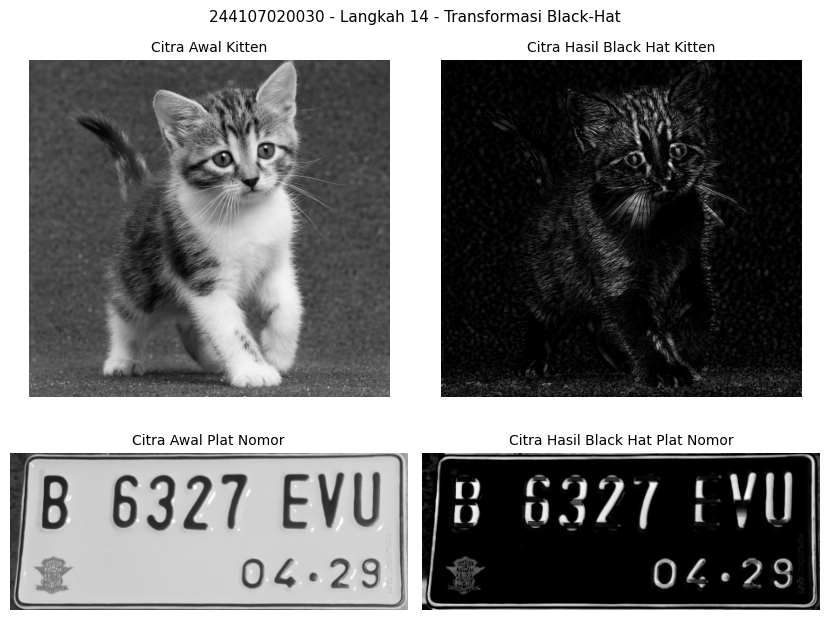

In [17]:
# Kernel Black-Hat sesuai kode modul
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))

blackhat_kit  = cv2.morphologyEx(img_kit,  cv2.MORPH_BLACKHAT, Kernel)
blackhat_plat = cv2.morphologyEx(img_gray, cv2.MORPH_BLACKHAT, Kernel)

print('Kitten     -> nilai maksimum Black-Hat:', blackhat_kit.max())
print('Plat Nomor -> nilai maksimum Black-Hat:', blackhat_plat.max())

tampilkan('Langkah 14 - Transformasi Black-Hat',
          [[(img_kit, 'Citra Awal Kitten'),
            (blackhat_kit, 'Citra Hasil Black Hat Kitten', blackhat_kit.max())],
           [(img_gray, 'Citra Awal Plat Nomor'),
            (blackhat_plat, 'Citra Hasil Black Hat Plat Nomor', blackhat_plat.max())]])

**Pembahasan Singkat**

Top-hat hanya menyisakan detail tipis yang lebih terang dari sekitarnya, misalnya bulu terang kucing dan tepi huruf plat. Hasil pada plat nomor lebih gelap karena bidangnya rata dan kontrasnya tinggi. Black-hat menyorot bagian gelap yang lebih kecil dari kernel, misalnya garis mata, kumis, dan tepi gelap huruf. Karena kernel (13, 5) cukup besar, sorotan black-hat lebih tebal daripada kernel 3x3.

---
## **Langkah 15 - Skeleton pada Citra Biner**

Skeleton atau rangka diambil dengan `skimage.morphology.skeletonize`. Hasilnya garis setebal satu piksel di tengah objek.

Lily -> ambang triangle 253, piksel rangka 15477
Plat Nomor -> ambang triangle 192, piksel rangka 3664


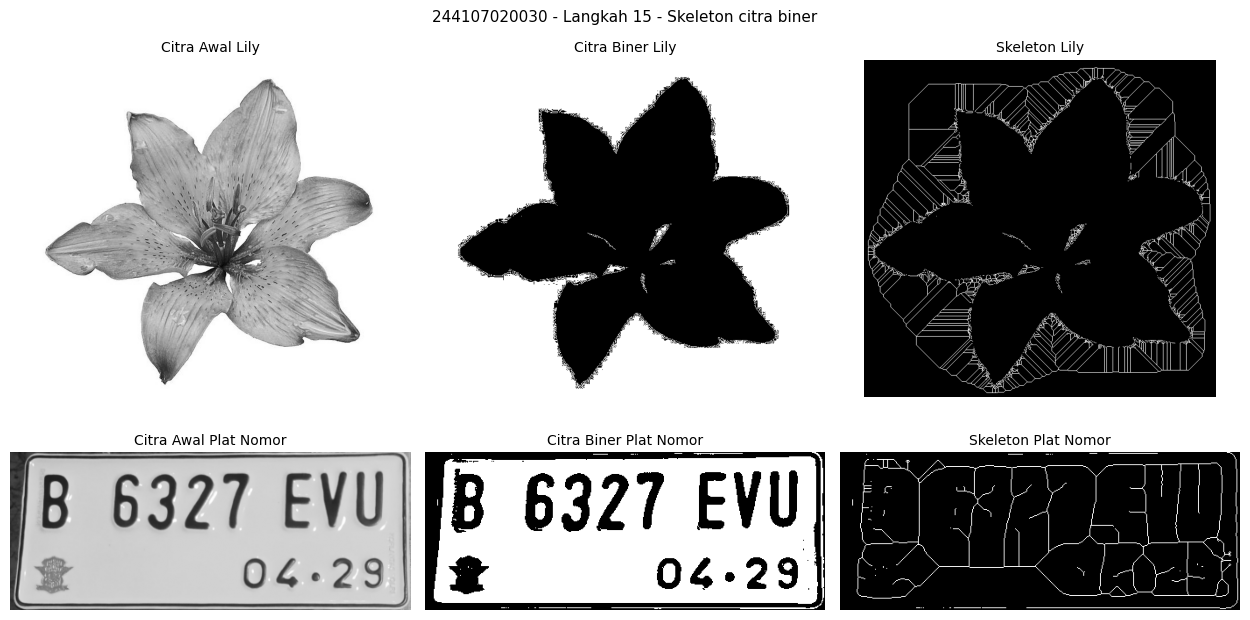

In [18]:
from skimage import filters
from skimage.morphology import skeletonize

img_lily = baca_citra(path_lily, cv2.IMREAD_GRAYSCALE)

baris = []
for nama, img in [('Lily', img_lily), ('Plat Nomor', img_gray)]:
    ambang = filters.threshold_triangle(img)
    binary = img > ambang
    skeleton = skeletonize(binary)
    print(f'{nama} -> ambang triangle {ambang:.0f}, piksel rangka {np.count_nonzero(skeleton)}')
    baris.append([(img, f'Citra Awal {nama}'),
                  (binary.astype(np.uint8) * 255, f'Citra Biner {nama}'),
                  (skeleton.astype(np.uint8) * 255, f'Skeleton {nama}')])

tampilkan('Langkah 15 - Skeleton citra biner', baris)

## **Langkah 16 - Skeleton pada Citra Inversi**

Sekarang kondisinya dibalik jadi `img < threshold`, sehingga bagian gelap yang dianggap objek.

Lily -> piksel rangka (img > t): 15477 | (img < t): 18916
Plat Nomor -> piksel rangka (img > t): 3664 | (img < t): 3394


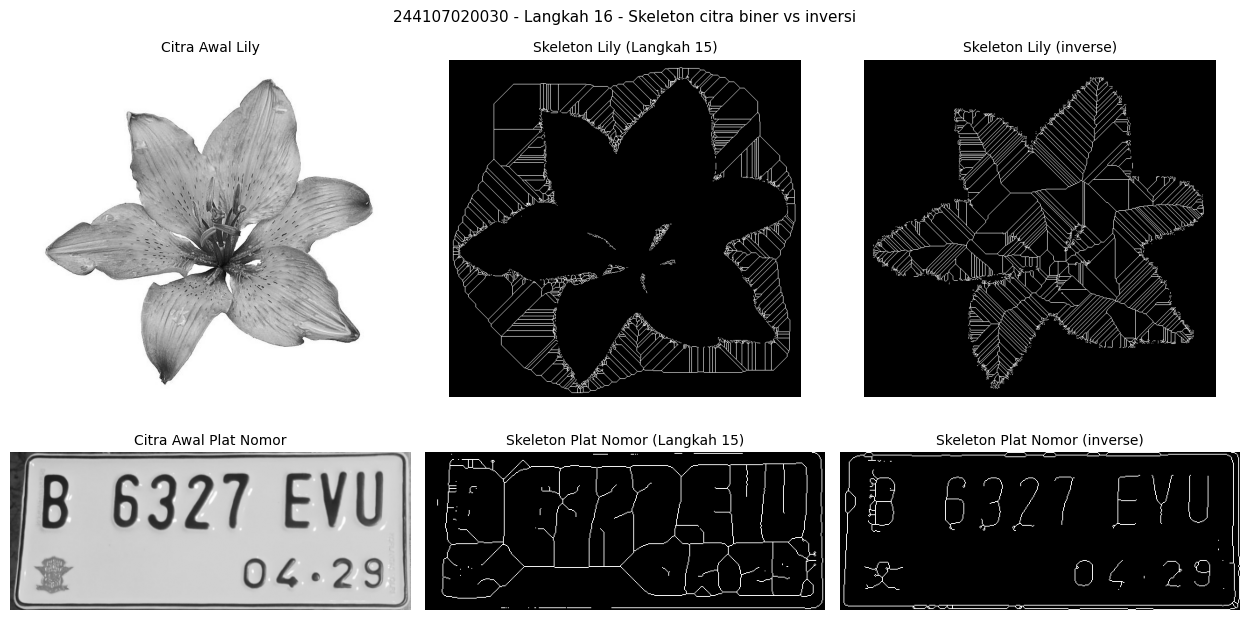

In [19]:
baris = []
for nama, img in [('Lily', img_lily), ('Plat Nomor', img_gray)]:
    ambang = filters.threshold_triangle(img)
    skel_terang = skeletonize(img > ambang)
    skel_gelap  = skeletonize(img < ambang)
    print(f'{nama} -> piksel rangka (img > t): {np.count_nonzero(skel_terang)} | '
          f'(img < t): {np.count_nonzero(skel_gelap)}')
    baris.append([(img, f'Citra Awal {nama}'),
                  (skel_terang.astype(np.uint8) * 255, f'Skeleton {nama} (Langkah 15)'),
                  (skel_gelap.astype(np.uint8) * 255, f'Skeleton {nama} (inverse)')])

tampilkan('Langkah 16 - Skeleton citra biner vs inversi', baris)

## **Langkah 17 - Thinning dengan morphology.thin()**

Thinning juga menipiskan objek jadi satu piksel, tetapi hasilnya tidak selalu garis tengah seperti `skeletonize`. Ambangnya 0,5 pada citra float.

Lily -> skeletonize 8998 piksel, thin 8929 piksel
Plat Nomor -> skeletonize 3296 piksel, thin 3268 piksel


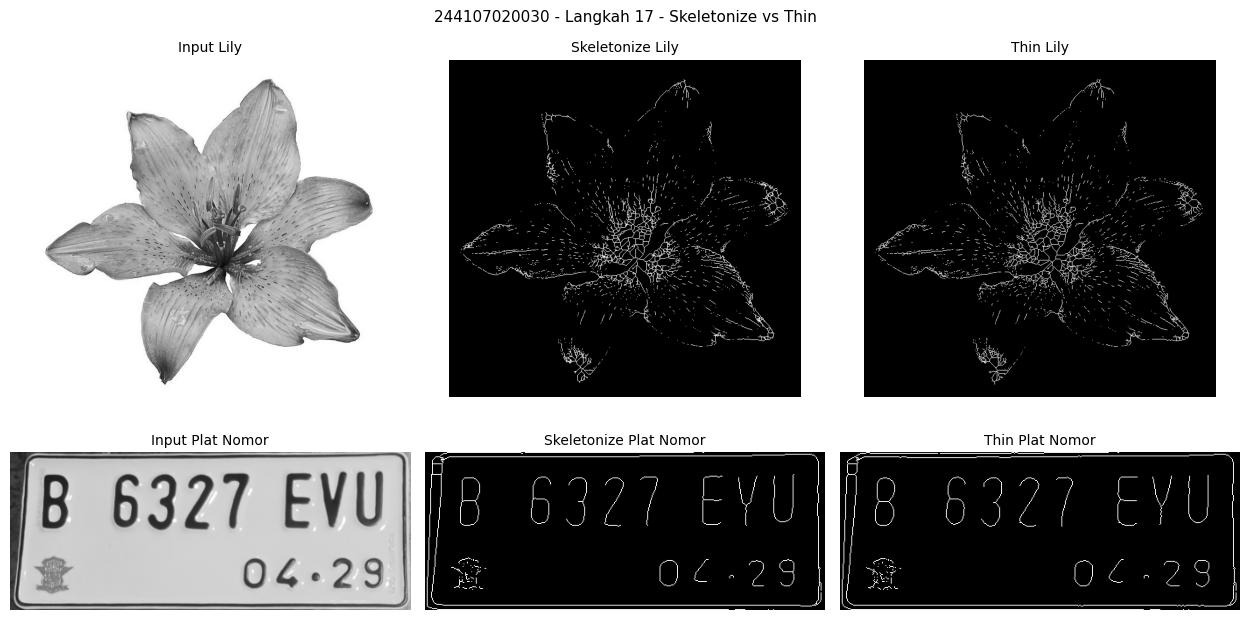

In [20]:
from skimage import img_as_float
from skimage.morphology import thin

baris = []
for nama, img in [('Lily', img_lily), ('Plat Nomor', img_gray)]:
    image = img_as_float(img / 255.0)
    image_binary = image < 0.5

    out_skeletonize = skeletonize(image_binary)
    out_thin = thin(image_binary)

    print(f'{nama} -> skeletonize {np.count_nonzero(out_skeletonize)} piksel, '
          f'thin {np.count_nonzero(out_thin)} piksel')

    baris.append([(image, f'Input {nama}'),
                  (out_skeletonize.astype(np.uint8) * 255, f'Skeletonize {nama}'),
                  (out_thin.astype(np.uint8) * 255, f'Thin {nama}')])

tampilkan('Langkah 17 - Skeletonize vs Thin', baris)

**Pembahasan Singkat**

Pada Langkah 15 bagian terang dianggap objek, jadi rangka plat nomor mengelilingi huruf dan rangka lily mengikuti garis luar bunga. Setelah diinversi, yang jadi objek adalah bagian gelap, sehingga jumlah piksel rangkanya berubah. Ini menunjukkan hasil skeleton bergantung pada mana yang dianggap objek, bukan hanya nilai ambangnya.

Pada Langkah 17 hasil `skeletonize` dan `thin` mirip, sama-sama setebal satu piksel. Bedanya, `skeletonize` mengambil garis tengah sehingga lebih halus, sedangkan `thin` mempertahankan lebih banyak cabang dan ujung goresan. Karena ambangnya 0,5 pada citra float, bagian gelap yang jadi objek, jadi hasilnya lebih mirip Langkah 16.